In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 19.4 — $F$-symbols and the pentagon system for the Ising fusion rules

**Source.** SMSA 7.8, 2026-11-05 (local `smsa.pdf`, SHA-256 `6922b174…813b8fe`). References are section and equation numbers of that version. **Translation conventions.** `f >> g` is SMSA's $g\circ f$ (first $f$, then $g$); `f @ g` is $f\otimes g$ with the left factor on the left. Native DisCoPy drawings read **top to bottom**, SMSA reads bottom to top; left-to-right order is unchanged. Only built-in DisCoPy 1.2.2 objects and methods are used: no custom functions, classes or rewrite rules. Checks print the computed and expected values with a comparison result and continue when a comparison is `False`.

**Fusion rules and $F$-symbols used here.** Labels $1$ (vacuum), $2$ ($\sigma$), $3$ ($\psi$) with the Ising fusion rules $2\times2=1+3$, $2\times3=2$, $3\times3=1$, and $1$ the unit. The $F$-symbol $(F^{abc}_d)_{ef}$ relates the coupling tree $((a\,b)_e\,c)_d$ to the tree $(a\,(b\,c)_f)_d$: $|((ab)_e c)_d\rangle=\sum_f (F^{abc}_d)_{ef}\,|(a(bc)_f)_d\rangle$. The numbers are the solution of the full pentagon system in the course notebook `from_fusion_to_solving_pentagon.nb`: unit gauge (an $F$ with a vacuum among $a,b,c$ equals $1$ when admissible), $F^{222}_2$ the Hadamard matrix with positive upper-left entry, and $(F^{232}_3)_{22}=(F^{323}_2)_{22}=-1$. SMSA's (19.25) defines $F^{(ijk)l}_{p,q}$ in the opposite direction, right tree in terms of left trees, which is the inverse matrix; every Ising $F$-matrix is real, symmetric and its own inverse, so the two conventions give the same numbers with $p$ read as the right channel and $q$ as the left channel.

The fusion table and the displayed F-symbols are supplied inputs. The $F$-symbols are stored as supplied numbers, then every component of the pentagon (19.30) is evaluated.

In [1]:
import numpy as np
labels = [1, 2, 3]                                    # 1 = vacuum, 2 = sigma, 3 = psi
fusion = {(1, 1): [1], (1, 2): [2], (1, 3): [3], (2, 1): [2], (3, 1): [3],
          (2, 2): [1, 3], (2, 3): [2], (3, 2): [2], (3, 3): [1]}
print('2 x 2 =', fusion[(2, 2)], '  expected [1, 3]:', fusion[(2, 2)] == [1, 3])
s = 1 / np.sqrt(2)
solved = {(2,2,2,2,1,1): s, (2,2,2,2,1,3): s, (2,2,2,2,3,1): s, (2,2,2,2,3,3): -s,
          (2,2,3,1,3,2): 1, (2,2,3,3,1,2): 1, (2,3,2,1,2,2): 1, (2,3,2,3,2,2): -1, (2,3,3,2,2,1): 1,
          (3,2,2,1,2,3): 1, (3,2,2,3,2,1): 1, (3,2,3,2,2,2): -1, (3,3,2,2,1,2): 1, (3,3,3,3,1,1): 1}
F = {}
for a in labels:
    for b in labels:
        for c in labels:
            for d in labels:
                for e in labels:
                    for f in labels:
                        admissible = e in fusion[(a, b)] and d in fusion[(e, c)] and f in fusion[(b, c)] and d in fusion[(a, f)]
                        F[(a, b, c, d, e, f)] = 0.0 if not admissible else (1.0 if 1 in (a, b, c) else solved[(a, b, c, d, e, f)])
nonzero = [key for key in F if F[key] != 0]
print('Admissible F-symbols:', len(nonzero), ' of which fixed to 1 by the unit gauge:', len(nonzero) - len(solved), ' solved:', len(solved))
print('F^{222}_2 with channels (1, 3):')
print(np.array([[F[(2, 2, 2, 2, e, f)] for f in (1, 3)] for e in (1, 3)]))
print('Expected Hadamard matrix:')
print(np.array([[1, 1], [1, -1]]) / np.sqrt(2))
print('(F^{232}_3)_{22} =', F[(2, 3, 2, 3, 2, 2)], '  (F^{323}_2)_{22} =', F[(3, 2, 3, 2, 2, 2)], '  expected -1, -1')

2 x 2 = [1, 3]   expected [1, 3]: True
Admissible F-symbols: 36  of which fixed to 1 by the unit gauge: 22  solved: 14
F^{222}_2 with channels (1, 3):
[[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
Expected Hadamard matrix:
[[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
(F^{232}_3)_{22} = -1   (F^{323}_2)_{22} = -1   expected -1, -1


**The two trees of (19.28).** For three objects of type $2$ coupled to total type $2$, the left tree $((2\,2)_e\,2)_2$ and the right tree $(2\,(2\,2)_f)_2$ each have two basis vectors, $e,f\in\{1,3\}$. The native drawing below uses one box per coupling vertex, named by its output channel; the matrix that expresses the left basis through the right basis is $F^{222}_2$ printed above. (SMSA's labels $i,j,k,l$ are all $2$ here, and the multiplicities $N$ of (19.27) are $0$ or $1$, so the basis indices $\alpha,\beta,\gamma,\delta$ are not needed.)

left tree : (2 2)_e @ 2 >> (e 2)_2   boundary 2 @ 2 @ 2 -> 2
right tree: 2 @ (2 2)_f >> (2 f)_2   boundary 2 @ 2 @ 2 -> 2
Same boundary: True


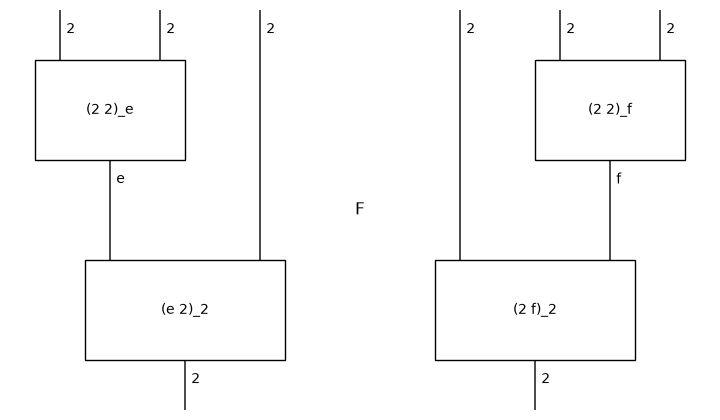

In [2]:
from discopy import monoidal
from discopy.drawing import Equation
two = monoidal.Ty('2')
pair_e = monoidal.Box('(2 2)_e', two @ two, monoidal.Ty('e'))
top_left = monoidal.Box('(e 2)_2', monoidal.Ty('e') @ two, two)
pair_f = monoidal.Box('(2 2)_f', two @ two, monoidal.Ty('f'))
top_right = monoidal.Box('(2 f)_2', two @ monoidal.Ty('f'), two)
left_tree = (pair_e @ monoidal.Id(two)) >> top_left
right_tree = (monoidal.Id(two) @ pair_f) >> top_right
print('left tree :', left_tree, '  boundary', left_tree.dom, '->', left_tree.cod)
print('right tree:', right_tree, '  boundary', right_tree.dom, '->', right_tree.cod)
print('Same boundary:', left_tree.dom == right_tree.dom and left_tree.cod == right_tree.cod)
Equation(left_tree, right_tree, symbol='   F   ').draw(figsize=(7, 4))

**The pentagon system (19.30).** For every admissible choice of the nine labels $(a,b,c,d,t;\,p,q,r,s)$, the long route through three $F$-moves must equal the short route through two, with the same index placement as in the course notebook:
$$\sum_x (F^{abc}_q)_{px}\,(F^{axd}_t)_{qr}\,(F^{bcd}_r)_{xs}=(F^{pcd}_t)_{qs}\,(F^{abs}_t)_{pr}.$$
SMSA's (19.30) is the same equality written with its own index names. The cell lists every admissible labelling and prints the largest residual.

In [3]:
labellings = [(a, b, c, d, t, p, q, r, s)
              for a in labels for b in labels for c in labels for d in labels for t in labels
              for p in labels for q in labels for r in labels for s in labels
              if p in fusion[(a, b)] and q in fusion[(p, c)] and t in fusion[(q, d)]
              and s in fusion[(c, d)] and r in fusion[(b, s)] and t in fusion[(a, r)]]
residuals = [sum(F[(a, b, c, q, p, x)] * F[(a, x, d, t, q, r)] * F[(b, c, d, r, x, s)] for x in labels)
             - F[(p, c, d, t, q, s)] * F[(a, b, s, t, p, r)]
             for (a, b, c, d, t, p, q, r, s) in labellings]
print('Admissible labellings of the pentagon:', len(labellings), '  expected 136:', len(labellings) == 136)
print('Largest |long route - short route| over all of them:', max(abs(r) for r in residuals))
print('All components hold (to 1e-12):', all(abs(r) < 1e-12 for r in residuals))
example = (2, 2, 2, 2, 3, 1, 2, 2, 3)
a, b, c, d, t, p, q, r, s = example
print('Example labelling', example, ': long route', round(sum(F[(a, b, c, q, p, x)] * F[(a, x, d, t, q, r)] * F[(b, c, d, r, x, s)] for x in labels), 12), ' short route', F[(p, c, d, t, q, s)] * F[(a, b, s, t, p, r)])

Admissible labellings of the pentagon: 136   expected 136: True
Largest |long route - short route| over all of them: 2.220446049250313e-16
All components hold (to 1e-12): True
Example labelling (2, 2, 2, 2, 3, 1, 2, 2, 3) : long route 1.0  short route 1.0


**A second pentagon block as diagrams.** The §19.3 notebook evaluates the block with four objects of type $2$ and total type $3$, where $HZH=X$. With total type $1$ the same five matrices become $H$, the identity and $H$ on the long route and two identities on the short route, so the block says $H^2=1$. The native `tensor` boxes carry the matrices; `eval()` multiplies them out.

In [4]:
from discopy import tensor
D2 = tensor.Dim(2)
Had = np.array([[F[(2, 2, 2, 2, e, f)] for f in (1, 3)] for e in (1, 3)])
middle = np.diag([F[(2, x, 2, 1, 2, 2)] for x in (1, 3)])
a_AB = tensor.Box('a(2,2,2) ⊗ id', D2, D2, Had)
a_BC = tensor.Box('a(2,(2 2),2)', D2, D2, middle)
a_CD = tensor.Box('id ⊗ a(2,2,2)', D2, D2, Had)
a_AE = tensor.Box('a((2 2),2,2)', D2, D2, np.diag([F[(p, 2, 2, 1, 2, p)] for p in (1, 3)]))
a_ED = tensor.Box('a(2,2,(2 2))', D2, D2, np.diag([F[(2, 2, s, 1, s, 2)] for s in (1, 3)]))
long_route = a_AB >> a_BC >> a_CD
short_route = a_AE >> a_ED
print('middle matrix (F^{2x2}_1)_{22}, x = 1, 3:', np.diag(middle))
print('Long route evaluated (rounded to 12 digits):')
print(np.round(long_route.eval().array, 12))
print('Short route evaluated:')
print(short_route.eval().array)
print('Pentagon block with total type 1 holds (NumPy allclose):', np.allclose(long_route.eval().array, short_route.eval().array))

middle matrix (F^{2x2}_1)_{22}, x = 1, 3: [1. 1.]
Long route evaluated (rounded to 12 digits):
[[ 1. -0.]
 [-0.  1.]]
Short route evaluated:
[[1. 0.]
 [0. 1.]]
Pentagon block with total type 1 holds (NumPy allclose): True


**Scope and placeholders.** The $F$-symbols are supplied numbers, taken from the solution of the pentagon system in the course notebook; this notebook verifies that solution component by component, it does not solve the polynomial system itself. The signs of $(F^{232}_3)_{22}$, $(F^{323}_2)_{22}$ and the overall sign of $F^{222}_2$ are gauge and branch choices (Remark 19.4.5); the lecture notes use $-H$, which changes nothing in the checks because $F^{222}_2$ always appears twice. The $sl(2)$ formula (19.31) is still a TODO in this version of SMSA and is not reconstructed here.

**Extracting the coefficients in (19.29).** The right and left coupling trees each have two channel coordinates, ordered $(1,3)$. The supplied Hadamard matrix changes from right-tree to left-tree coordinates in this real self-inverse example. A coordinate state selects $p$ and a dual coordinate costate selects $q$, so their composite with that matrix gives the single coefficient $F_{pq}$.

The fully labelled source network also contains the external simple objects and chosen dual closing morphisms. First we draw that network as free typed syntax for $i=j=k=l=2$, $p=q=3$. The boxes marked `close` are the chosen paired basis morphisms of the text after (19.29). They are not assigned ordinary vector dimensions or arrays here. The two pictures state the source's equality, not a native rewrite.

For evaluation we then use only the fusion-channel coordinate space. `Dim(2)` means its two channels, not the simple Ising object labelled 2. The four scalar contractions reproduce the four supplied matrix entries. A second check closes a rank-one operator with a native ordinary trace. This is an auxiliary channel-space contraction, not an evaluation of every wire in the full source network. No general rigid Ising realization is being supplied.

(19.29) closed-network boundaries: Ty() -> Ty() and Ty() -> Ty()


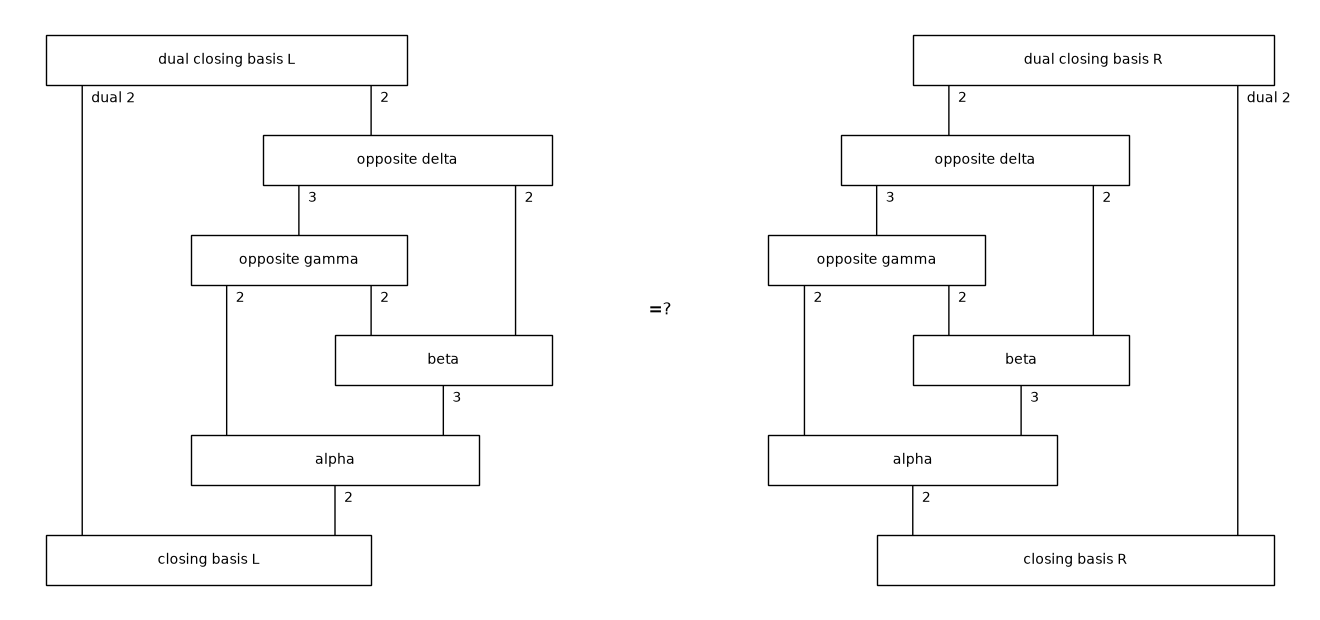

In [5]:
from discopy import monoidal
simple = monoidal.Ty('2')
channel = monoidal.Ty('3')
dual_simple = monoidal.Ty('dual 2')
alpha = monoidal.Box('alpha', simple @ channel, simple)
beta = monoidal.Box('beta', simple @ simple, channel)
gamma_op = monoidal.Box('opposite gamma', channel, simple @ simple)
delta_op = monoidal.Box('opposite delta', simple, channel @ simple)
network = delta_op >> (gamma_op @ monoidal.Id(simple)) >> (monoidal.Id(simple) @ beta) >> alpha
close_left_in = monoidal.Box('dual closing basis L', monoidal.Ty(), dual_simple @ simple)
close_left_out = monoidal.Box('closing basis L', dual_simple @ simple, monoidal.Ty())
close_right_in = monoidal.Box('dual closing basis R', monoidal.Ty(), simple @ dual_simple)
close_right_out = monoidal.Box('closing basis R', simple @ dual_simple, monoidal.Ty())
closed_left = close_left_in >> (monoidal.Id(dual_simple) @ network) >> close_left_out
closed_right = close_right_in >> (network @ monoidal.Id(dual_simple)) >> close_right_out
print('(19.29) closed-network boundaries:', closed_left.dom, '->', closed_left.cod, 'and', closed_right.dom, '->', closed_right.cod)
Equation(closed_left, closed_right, symbol='=?').draw(figsize=(13,6))


p,q = 1 1 scalar: 0.7071067811865475 expected: 0.7071067811865475 equal: True
p,q = 1 3 scalar: 0.7071067811865475 expected: 0.7071067811865475 equal: True
p,q = 3 1 scalar: 0.7071067811865475 expected: 0.7071067811865475 equal: True
p,q = 3 3 scalar: -0.7071067811865475 expected: -0.7071067811865475 equal: True
All four scalar contractions:
 [[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
All four auxiliary closed traces:
 [[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
Expected supplied F matrix:
 [[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
Both match: True
Control: replace q=3 by q=1: 0.7071067811865475 required F_33: -0.7071067811865475
Still F_33 (expected False): False


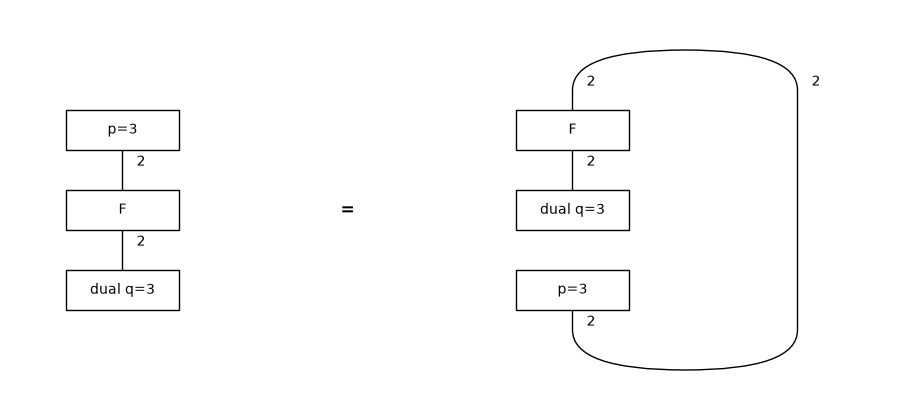

In [6]:
channel_space = tensor.Dim(2)
F_channels = tensor.Box('F', channel_space, channel_space, Had)
extracted = np.zeros((2,2))
closed_trace = np.zeros((2,2))
for row, p in enumerate((1,3)):
    for col, q in enumerate((1,3)):
        select_p = tensor.Box('p='+str(p), tensor.Dim(), channel_space, np.eye(2)[row])
        select_q = tensor.Box('dual q='+str(q), channel_space, tensor.Dim(), np.eye(2)[col])
        coefficient = select_p >> F_channels >> select_q
        rank_one = F_channels >> select_q >> select_p
        extracted[row,col] = coefficient.eval().array.item()
        closed_trace[row,col] = rank_one.trace().eval().array.item()
        print('p,q =',p,q,'scalar:',extracted[row,col], 'expected:',Had[row,col], 'equal:',np.isclose(extracted[row,col],Had[row,col],rtol=0,atol=1e-12))
print('All four scalar contractions:\n',extracted)
print('All four auxiliary closed traces:\n',closed_trace)
print('Expected supplied F matrix:\n',Had)
print('Both match:', np.allclose(extracted,Had,rtol=0,atol=1e-12) and np.allclose(closed_trace,Had,rtol=0,atol=1e-12))
# Last pair p=q=3 displays the negative coefficient.
Equation(coefficient, rank_one.trace()).draw(figsize=(9,4))
wrong_q = tensor.Box('dual q=1',channel_space,tensor.Dim(),[1,0])
wrong_value = (select_p >> F_channels >> wrong_q).eval().array.item()
print('Control: replace q=3 by q=1:',wrong_value,'required F_33:',Had[1,1])
print('Still F_33 (expected False):',np.isclose(wrong_value,Had[1,1],rtol=0,atol=1e-12))


### Why the simple-object wires are not ordinary tensor dimensions

**DC-07 assessment.** Keep the supplied Ising fusion rules: $\psi\otimes\psi\cong1$ and $\sigma\otimes\sigma\cong1\oplus\psi$ (labels 3 and 2 respectively). If we assign ordinary finite-dimensional vector spaces to these objects, preserving the unit, tensor products and direct sums, their dimensions must obey
$$d_1=1,\qquad d_\psi^2=1,\qquad d_\sigma^2=1+d_\psi.$$
Since dimensions are nonnegative integers, $d_\psi=1$ and $d_\sigma^2=2$. This has no integer solution: $d_\sigma=0$ or 1 gives a square at most 1, and $d_\sigma\ge2$ gives a square at least 4. This is an obstruction for every integer dimension, not just the two candidates printed below.

Thus a linear interpretation preserving these structures cannot send all Ising simple-object wires to ordinary `tensor.Dim` wires. Changing basis, rescaling a closing map, or choosing a different sign of the Hadamard matrix cannot fix this dimension mismatch. The paired closing bases in SMSA p.435 after (19.29) must also be distinguished from unnormalised ordinary trace cups/caps.

The current `Dim(2)` is still legitimate: it is the two-dimensional **fusion-channel coordinate space** with basis $(1,\psi)$. It is not a realization of $\sigma$. The following deliberately chosen compression of a four-dimensional tensor product to two channels demonstrates the distinction. One composite is the identity on channels; the reverse composite is only a rank-two projector. These boxes are a control, not proposed Ising fusion vertices.


In [7]:
# SMSA7.8 (19.29), pp434–435: assessment for the supplied Ising model.
for candidate_sigma_dim in (1, 2):
    print('Candidate d_sigma:', candidate_sigma_dim,
          '; sigma tensor sigma size:', candidate_sigma_dim**2,
          '; required 1 plus psi size:', 2,
          '; equal:', candidate_sigma_dim**2 == 2)
compression_array = np.array([[1,0], [0,1], [0,0], [0,0]])
compression = tensor.Box('illustrative compression', tensor.Dim(2,2), tensor.Dim(2), compression_array)
section = tensor.Box('illustrative section', tensor.Dim(2), tensor.Dim(2,2), compression_array.T)
channel_roundtrip = (section >> compression).eval().array
wire_roundtrip = (compression >> section).eval().array.reshape(4,4)
print('Channel round trip, expected I2:\n', channel_roundtrip)
print('Channel identity:', np.array_equal(channel_roundtrip, np.eye(2)))
print('Wire round trip:\n', wire_roundtrip, '\nRequired for an isomorphism: I4\n', np.eye(4))
print('Wire identity (expected False):', np.array_equal(wire_roundtrip, np.eye(4)))
print('Rank of wire round trip:', np.linalg.matrix_rank(wire_roundtrip), '; full wire dimension:', 4)


Candidate d_sigma: 1 ; sigma tensor sigma size: 1 ; required 1 plus psi size: 2 ; equal: False
Candidate d_sigma: 2 ; sigma tensor sigma size: 4 ; required 1 plus psi size: 2 ; equal: False
Channel round trip, expected I2:
 [[1 0]
 [0 1]]
Channel identity: True
Wire round trip:
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 0 0]
 [0 0 0 0]] 
Required for an isomorphism: I4
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Wire identity (expected False): False
Rank of wire round trip: 2 ; full wire dimension: 4


### What native matrices can still represent

There is also a small native matrix representation of the **fusion rules**, distinct from the $F$-matrix on tree channels. On the three-dimensional bookkeeping space with basis $(1,\sigma,\psi)$, let $N_a$ act by multiplying a basis label by $a$ and listing its fusion multiplicities. Then $N_\sigma^2=I+N_\psi$ and $N_\psi^2=I$. Here multiplication is diagram composition on one bookkeeping wire, and addition is addition of maps. It does not turn the labels into simple-object tensor wires or evaluate the closing vertices of (19.29).


In [8]:
fusion_bookkeeping = tensor.Dim(3)
N_sigma_values = np.array([[0,1,0], [1,0,1], [0,1,0]])
N_psi_values = np.array([[0,0,1], [0,1,0], [1,0,0]])
N_sigma = tensor.Box('multiply by sigma', fusion_bookkeeping, fusion_bookkeeping, N_sigma_values.T)
N_psi = tensor.Box('multiply by psi', fusion_bookkeeping, fusion_bookkeeping, N_psi_values.T)
N_unit = tensor.Id(fusion_bookkeeping)
print('Fusion matrices, column convention, basis 1,sigma,psi:\n', N_sigma_values, '\n', N_psi_values)
print('N_sigma composed with itself:\n', (N_sigma >> N_sigma).eval().array.T)
print('Expected I plus N_psi:\n', np.eye(3, dtype=int)+N_psi_values)
print('Sigma fusion holds:', np.array_equal((N_sigma >> N_sigma).eval().array, (N_unit + N_psi).eval().array))
print('Psi squared is unit:', np.array_equal((N_psi >> N_psi).eval().array, N_unit.eval().array))
print('Boundaries of every N: Dim(3) -> Dim(3); these are operators on labels, not simple objects.')


Fusion matrices, column convention, basis 1,sigma,psi:
 [[0 1 0]
 [1 0 1]
 [0 1 0]] 
 [[0 0 1]
 [0 1 0]
 [1 0 0]]
N_sigma composed with itself:
 [[1 0 1]
 [0 2 0]
 [1 0 1]]
Expected I plus N_psi:
 [[1 0 1]
 [0 2 0]
 [1 0 1]]
Sigma fusion holds: True
Psi squared is unit: True
Boundaries of every N: Dim(3) -> Dim(3); these are operators on labels, not simple objects.


**Conclusion for (19.29).** The full labelled diagram remains useful typed syntax. Its Ising coefficients are evaluated in the fusion-channel calculation above. A faithful ordinary finite-array interpretation of all simple-object wires, preserving the given fusion structure, is ruled out by the dimension argument. A full evaluator would instead need fusion-tree/morphism-space semantics: admissible channels, associator and duality maps, paired closing bases and their normalization. The inspected DisCoPy 1.2.2 package has no ready-made Ising fusion target. Adding such semantics is outside this direct-library task; it is not a missing array assignment. This conclusion is about the selected Ising model, not all categories to which SMSA's (19.29) applies.
